## 5.1 — Local sanity check

Verify Ultralytics reads data_set_yolo/ correctly before GPU training.
No training happens here — only validation of data + config.

In [1]:
from pathlib import Path
from ultralytics import YOLO
import yaml

ROOT = Path(r"C:\Users\ycode\Desktop\2nd_YouCode\briefs\MRI_class_DL")
YAML = ROOT / "data_set_yolo" / "data.yaml"

# Load yaml
with open(YAML) as f:
    cfg = yaml.safe_load(f)
print("data.yaml:")
for k, v in cfg.items():
    print(f"  {k}: {v}")

# Load base model
model = YOLO("yolov8n.pt")
print(f"\nPretrained YOLOv8n classes: {len(model.names)} COCO classes")

data.yaml:
  path: C:\Users\ycode\Desktop\2nd_YouCode\briefs\MRI_class_DL\data_set_yolo
  train: images/train
  val: images/val
  test: images/test
  nc: 4
  names: {0: 'Glioma', 1: 'Meningioma', 2: 'No Tumor', 3: 'Pituitary'}

Pretrained YOLOv8n classes: 80 COCO classes


In [2]:
from ultralytics.data.utils import check_det_dataset

try:
    info = check_det_dataset(str(YAML))
    print("\n✅ Dataset validated by Ultralytics")
    print(f"   train path: {info['train']}")
    print(f"   val path:   {info['val']}")
    print(f"   test path:  {info.get('test', 'not set')}")
    print(f"   nc (classes): {info['nc']}")
    print(f"   names: {info['names']}")
except Exception as e:
    print(f"\n❌ Dataset check failed: {e}")
    raise


✅ Dataset validated by Ultralytics
   train path: C:\Users\ycode\Desktop\2nd_YouCode\briefs\MRI_class_DL\data_set_yolo\images\train
   val path:   C:\Users\ycode\Desktop\2nd_YouCode\briefs\MRI_class_DL\data_set_yolo\images\val
   test path:  C:\Users\ycode\Desktop\2nd_YouCode\briefs\MRI_class_DL\data_set_yolo\images\test
   nc (classes): 4
   names: {0: 'Glioma', 1: 'Meningioma', 2: 'No Tumor', 3: 'Pituitary'}


In [3]:
for split in ["train", "val", "test"]:
    imgs = list((ROOT / "data_set_yolo" / "images" / split).glob("*.jpg"))
    lbls = list((ROOT / "data_set_yolo" / "labels" / split).glob("*.txt"))
    empty = sum(1 for p in lbls if not p.read_text().strip())
    print(f"{split:6s}: {len(imgs):4d} img / {len(lbls):4d} lbl / {empty:4d} empty (negatives)")

train : 4026 img / 4026 lbl /  604 empty (negatives)
val   :  511 img /  511 lbl /  100 empty (negatives)
test  :  711 img /  711 lbl /  107 empty (negatives)


In [4]:
sample_lbl = next((ROOT / "data_set_yolo" / "labels" / "train").glob("*.txt"))
sample_img = ROOT / "data_set_yolo" / "images" / "train" / f"{sample_lbl.stem}.jpg"

print(f"Image: {sample_img.name}")
print(f"Label: {sample_lbl.name}")
print(f"Content:")
for line in sample_lbl.read_text().splitlines()[:5]:
    print(f"  {line}")

Image: Glioma__gg (1).jpg
Label: Glioma__gg (1).txt
Content:
  0 0.567383 0.519531 0.189453 0.148438


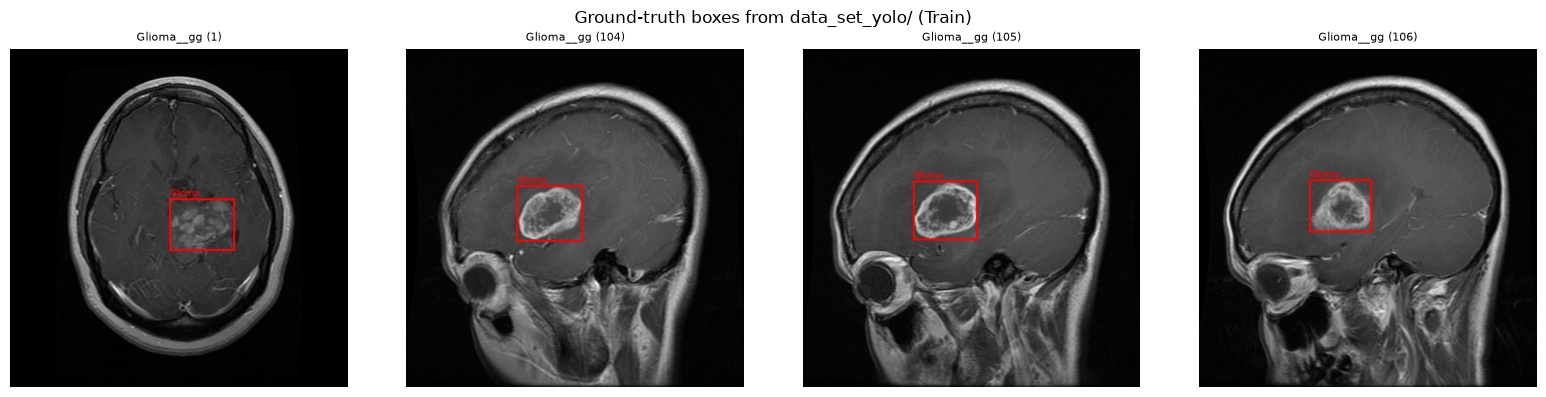

In [5]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Find a training image that has at least 1 box
candidates = []
for lbl in (ROOT / "data_set_yolo" / "labels" / "train").glob("*.txt"):
    if lbl.read_text().strip():
        candidates.append(lbl)
        if len(candidates) >= 4:
            break

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
CLASSES = ["Glioma", "Meningioma", "No Tumor", "Pituitary"]
COLORS  = [(255, 0, 0), (0, 255, 0), (0, 165, 255), (0, 255, 255)]  # BGR

for ax, lbl_path in zip(axes, candidates):
    img_path = ROOT / "data_set_yolo" / "images" / "train" / f"{lbl_path.stem}.jpg"
    img = cv2.imread(str(img_path))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    H, W = img.shape[:2]

    for line in lbl_path.read_text().splitlines():
        cid, xc, yc, w, h = line.split()
        cid, xc, yc, w, h = int(cid), float(xc), float(yc), float(w), float(h)
        x1 = int((xc - w/2) * W); y1 = int((yc - h/2) * H)
        x2 = int((xc + w/2) * W); y2 = int((yc + h/2) * H)
        cv2.rectangle(img, (x1, y1), (x2, y2), COLORS[cid], 2)
        cv2.putText(img, CLASSES[cid], (x1, y1-4), cv2.FONT_HERSHEY_SIMPLEX,
                    0.5, COLORS[cid], 1)

    ax.imshow(img); ax.set_title(lbl_path.stem, fontsize=8); ax.axis("off")

plt.suptitle("Ground-truth boxes from data_set_yolo/ (Train)")
plt.tight_layout(); plt.show()

## 5.6 — Step 5 findings & decision

### What we built
YOLOv8n fine-tuned on `data_set_yolo/` (4026 train / 511 val / 711 test):
- 4 classes defined in `data.yaml`: Glioma, Meningioma, No Tumor, Pituitary
- **No Tumor labels are empty** (negatives) — the model learns "no boxes here"
- Class-3 (Pituitary) anatomical noise stripped from Glioma/Meningioma folders during preprocessing
- 50 epochs, batch 16, imgsz 640, AdamW auto-LR, standard Ultralytics augmentation (mosaic, flips, HSV, degrees=10, translate=0.1, scale=0.5)

### Results — test set (711 images)

| Metric | Value |
|---|---|
| **mAP@0.5** | **0.9551** |
| **mAP@0.5:0.95** | **0.7393** |
| Precision | 0.936 |
| Recall | 0.908 |

**Per class (test):**
| Class | Precision | Recall | mAP50 | mAP50-95 |
|---|---|---|---|---|
| Glioma | 0.913 | 0.814 | 0.902 | 0.687 |
| Meningioma | 0.969 | 0.986 | 0.990 | 0.806 |
| Pituitary | 0.925 | 0.924 | 0.974 | 0.725 |

### Visual analysis
10 test images visualized in `reports/yolo_predictions/`. All show correctly drawn bounding boxes on visible tumor regions with high confidence scores.

### Decisions
- **Deploy** `models/yolo_brain_mri_best.pt` (6.5 MB — small enough for the Docker image).
- No Tumor is correctly excluded from detection evaluation (no GT boxes, purely a negative class).
- Glioma recall (0.814) is the weakest metric, likely due to irregular tumor boundaries; acceptable for this project. Improvement path: more Glioma samples or higher `imgsz`.

### Files produced
- `models/yolo_brain_mri_best.pt` — final detection weights
- `reports/eval_yolo.json` — test metrics
- `reports/yolo_predictions/pred_*.jpg` — visual predictions
- `reports/yolo_confusion_matrix.png`, `yolo_PR_curve.png`, `yolo_results.png`
- `runs/yolo_brain_mri/` — full Ultralytics logs and cache